# EfficientNet_06: EfficientNet-B0, grouped split (34 species, unseen recordings), 3 seeds

**Change vs 04: checkpoint selection on validation macro-F1** (same reason as EfficientNet_05). Augmentation as in 04: random low-pass, SpecAugment, noise, random time offset. Augmentation slows learning down, so it was hurt most by stopping at epoch 1.
lr 1e-4, weight decay 1e-2, max 15 epochs, patience 4 (on val F1).

Everything else is the 2025 recipe (see `EfficientNet_02.ipynb`). **Selection rule:** runs are compared on mean
*validation* macro-F1 over seeds 42/43/44; test metrics are recorded but not used for choosing.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
from src.EfficientNet.experiment import run_seeds
RUN = "EfficientNet_06"
df = run_seeds(RUN, split="grouped", augment=True, lr=1e-4, weight_decay=1e-2, max_epochs=15, patience=4, select_metric="val_f1")
df

device=cuda | classes=34 | train=9502 val=2102 test=2057


Epoch 1/15 | train loss 2.4645 acc 44.51 | val loss 2.8055 acc 24.41 F1 0.162 | lr 1.00e-04 | 116s


  saved best checkpoint -> efficientnet_06_s42_best_01.pth


Epoch 2/15 | train loss 1.1881 acc 71.78 | val loss 3.0458 acc 31.21 F1 0.248 | lr 1.00e-04 | 39s


  saved best checkpoint -> efficientnet_06_s42_best_01.pth


Epoch 3/15 | train loss 0.7510 acc 80.56 | val loss 3.3000 acc 34.30 F1 0.286 | lr 1.00e-04 | 38s


... (50 outputs left out)

  early stopping (no val_f1 improvement for 4 epochs)


Training finished.


--> EfficientNet_06_s44: val F1 0.347 acc 0.431 | best epoch 7/11


,run,seed,split,config,best_epoch,epochs_run,val_loss,val_acc,val_f1_macro,test_acc,test_f1_macro,minutes
0,EfficientNet_06,42,grouped,"{""augment"": true, ""lr"": 0.0001, ""weight_decay""...",4,8,3.5903,0.3877,0.3272,0.6067,0.4340,11.7
1,EfficientNet_06,43,grouped,"{""augment"": true, ""lr"": 0.0001, ""weight_decay""...",7,11,4.2594,0.4082,0.3576,0.6592,0.4155,7.4
2,EfficientNet_06,44,grouped,"{""augment"": true, ""lr"": 0.0001, ""weight_decay""...",7,11,3.4745,0.4310,0.3466,0.7394,0.5032,7.4


In [3]:
df[["val_f1_macro", "val_acc", "test_f1_macro", "test_acc", "best_epoch"]].agg(["mean", "std"]).round(3)

,val_f1_macro,val_acc,test_f1_macro,test_acc,best_epoch
mean,0.344,0.409,0.451,0.668,6.000
std,0.015,0.022,0.046,0.067,1.732


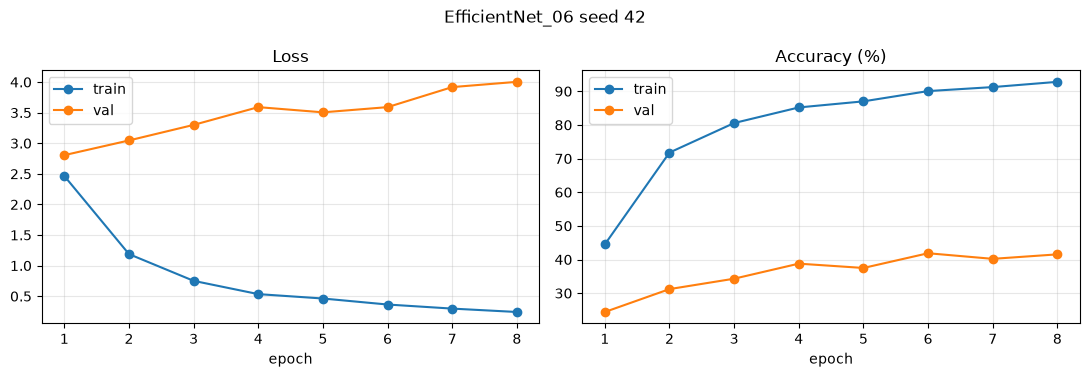

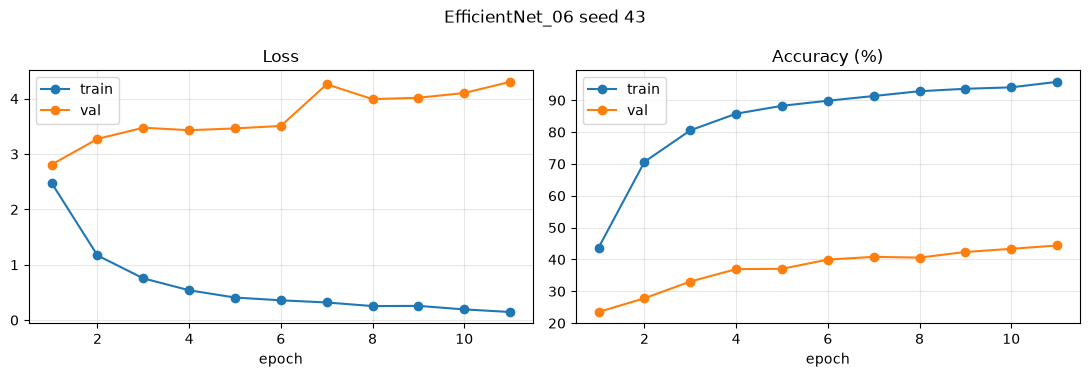

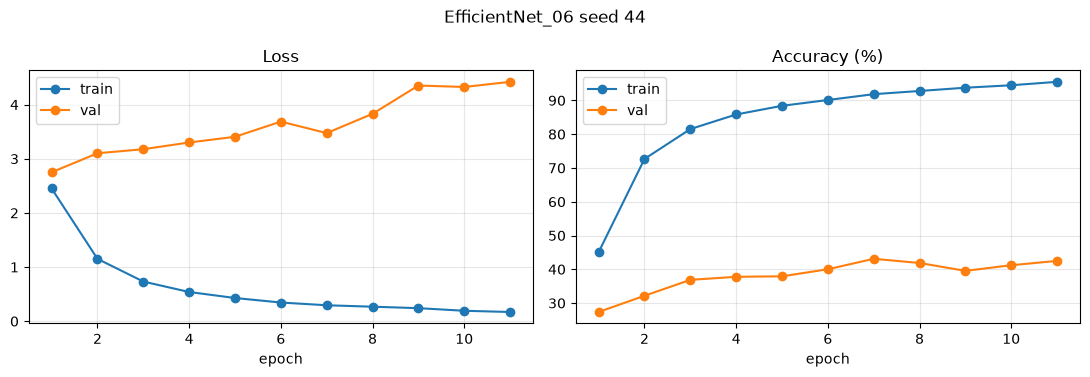

In [4]:
from src.plot_analysis import plot_learning_curves
import matplotlib.pyplot as plt
for s in df.seed:
    h = sorted(config.MODELS_OUTPUT.glob(f"{RUN.lower()}_s{s}_best_*_training_history.csv"))[-1]
    plot_learning_curves(h, f"{RUN} seed {s}", config.EVAL_DIR / f"learning_curves_{RUN}_s{s}.png"); plt.show()